# Q2 learning curve

In [2]:
import os
import sys
from pathlib import Path

# Current project folder
PROJECT_DIR = Path.cwd()

# Local Kaggle data folder
DATA_DIR = PROJECT_DIR / "data"

# Set paths
sys.path.insert(0, str(PROJECT_DIR))
os.environ["HOA_DATA"] = str(DATA_DIR)

# Check files
print("Project directory:", PROJECT_DIR)
print("common.py exists:", (PROJECT_DIR / "common.py").exists())
print("train.csv exists:", (DATA_DIR / "train.csv").exists())

Project directory: C:\Users\zhouy\Desktop\ct\aml\kagglemid\human-or-ai-submissions-group-16\submissions\group-16
common.py exists: True
train.csv exists: True


In [3]:
from common import SEED, get_split, normalize_ws

train_df, val_df = get_split()

print("Random seed:", SEED)
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))

display(train_df.head())

Random seed: 42
Training samples: 8000
Validation samples: 2000


,id,text,label
0,1,Cipriani S.A. is an Italian hotel and leisure ...,0
1,2,My Grandpa passed away 3 years ago from cancer...,0
2,3,"""Petit Beurre -- Butter Cookies\n\n1 cup (2 st...",1
3,4,"In an unprecedented move, a dedicated gamer ha...",1
4,5,Chile's copper industry has registered record ...,0


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.base import clone
from sklearn.metrics import roc_auc_score

from q1_model_comparison import build_models, score

# Word TF-IDF + Logistic Regression
description, base_model, grid = build_models(
    quick=True
)["A_word_tfidf_lr"]

base_model.set_params(
    vec__ngram_range=(1, 2),
    vec__min_df=2,
    clf__C=1.0
)

print("Model:", description)
print("Random Seed:", SEED)

Model: Word TF-IDF (unigram/bigram, punctuation kept as tokens) + logistic regression
Random Seed: 42


In [5]:

X_train = normalize_ws(
    train_df["text"].fillna("").astype(str).values
)
y_train = train_df["label"].values

X_val = normalize_ws(
    val_df["text"].fillna("").astype(str).values
)
y_val = val_df["label"].values

train_sizes = [500, 1000, 2000, 5000, 8000]

class_indices = {}

for label in [0, 1]:
    indices = np.where(y_train == label)[0]
    rng = np.random.default_rng(SEED + label)
    class_indices[label] = rng.permutation(indices)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Class distribution:", np.bincount(y_train))

Training samples: 8000
Validation samples: 2000
Class distribution: [4000 4000]


In [6]:
results = []

for n in train_sizes:

    print(f"\nTraining with {n} samples...")

    
    n_human = n // 2
    n_ai = n - n_human

    selected_indices = np.concatenate([
        class_indices[0][:n_human],
        class_indices[1][:n_ai]
    ])

    # current exp data
    X_subset = X_train[selected_indices]
    y_subset = y_train[selected_indices]

    # repeat training
    model = clone(base_model)
    model.fit(X_subset, y_subset)

    
    train_scores = score(model, X_subset)
    val_scores = score(model, X_val)

    # calculate AUROC
    train_auc = roc_auc_score(y_subset, train_scores)
    val_auc = roc_auc_score(y_val, val_scores)

    results.append({
        "Training Size": n,
        "Train AUROC": train_auc,
        "Validation AUROC": val_auc
    })

    print(f"Train AUROC: {train_auc:.4f}")
    print(f"Validation AUROC: {val_auc:.4f}")


results_df = pd.DataFrame(results)

display(results_df.round(4))


Training with 500 samples...
Train AUROC: 1.0000
Validation AUROC: 0.8924

Training with 1000 samples...
Train AUROC: 0.9998
Validation AUROC: 0.9122

Training with 2000 samples...
Train AUROC: 0.9986
Validation AUROC: 0.9315

Training with 5000 samples...
Train AUROC: 0.9977
Validation AUROC: 0.9448

Training with 8000 samples...
Train AUROC: 0.9968
Validation AUROC: 0.9523


,Training Size,Train AUROC,Validation AUROC
0,500,1.0000,0.8924
1,1000,0.9998,0.9122
2,2000,0.9986,0.9315
3,5000,0.9977,0.9448
4,8000,0.9968,0.9523


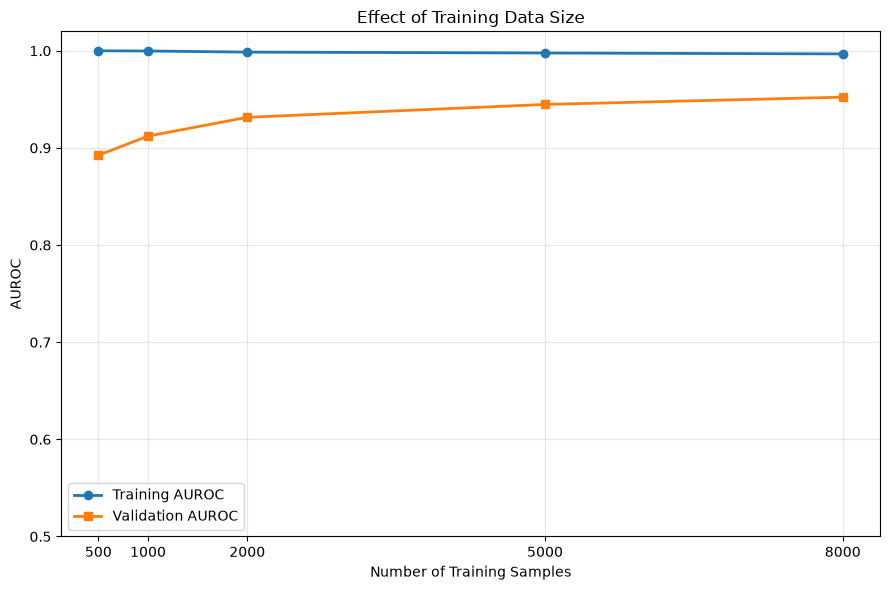

In [7]:
plt.figure(figsize=(9, 6))

plt.plot(
    results_df["Training Size"],
    results_df["Train AUROC"],
    marker="o",
    linewidth=2,
    label="Training AUROC"
)

plt.plot(
    results_df["Training Size"],
    results_df["Validation AUROC"],
    marker="s",
    linewidth=2,
    label="Validation AUROC"
)

plt.xlabel("Number of Training Samples")
plt.ylabel("AUROC")
plt.title("Effect of Training Data Size")

plt.xticks(train_sizes)
plt.ylim(0.5, 1.02)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

output_dir = Path(PROJECT_DIR) / "results"
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "q2_learning_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


results_df.to_csv(
    output_dir / "q2_training_size.csv",
    index=False
)

### Q2.3 
The learning curve shows that validation AUROC increases as the training set becomes larger. It rises from approximately 0.893 with 500 samples to 0.953 with 8,000 samples. Meanwhile, training AUROC stays close to 1.0 across all training sizes. This suggests some overfitting, especially when the model is trained on fewer samples. However, the gap between training and validation performance becomes smaller as more data is added. The improvement also becomes slower after 2,000 samples, which suggests diminishing returns from additional training data. Overall, the model does not appear to suffer from serious underfitting. More labeled examples help improve generalization, although the benefits become smaller at larger training sizes.

### Q3

In [9]:
from common import load_csv

unlabeled_df = load_csv("unlabeled.csv")

print("Unlabeled samples:", len(unlabeled_df))
print("Columns:", unlabeled_df.columns.tolist())

display(unlabeled_df.head())


Unlabeled samples: 3000
Columns: ['id', 'text']


,id,text
0,10001,Sergei Shemetov (Russian: Серге́й Шеметов; bor...
1,10002,Venezuelan authorities have identified more th...
2,10003,So every house on my street has high school ki...
3,10004,Uri: The Surgical Strike is a cinematic master...
4,10005,"This report describes the design, implementati..."


In [10]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import roc_auc_score
from q1_model_comparison import build_models

# use same model in Q2
_, base_model_q3, _ = build_models(
    quick=True
)["A_word_tfidf_lr"]

base_model_q3.set_params(
    vec__ngram_range=(1, 2),
    vec__min_df=2,
    clf__C=1.0
)

# prepare data
X_train = normalize_ws(
    train_df["text"].fillna("").astype(str).values
)
y_train = train_df["label"].values

X_val = normalize_ws(
    val_df["text"].fillna("").astype(str).values
)
y_val = val_df["label"].values

# train supervised learning Baseline
baseline = clone(base_model_q3)
baseline.fit(X_train, y_train)

# calculate AUROC
baseline_prob = baseline.predict_proba(X_val)[:, 1]
baseline_auc = roc_auc_score(y_val, baseline_prob)

print(f"Baseline Validation AUROC: {baseline_auc:.4f}")

Baseline Validation AUROC: 0.9523


In [11]:
# 3000 unlabeled text
X_unlabeled = normalize_ws(
    unlabeled_df["text"].fillna("").astype(str).values
)

# use Baseline predict AI prob
unlabeled_prob = baseline.predict_proba(
    X_unlabeled
)[:, 1]

# set threshold
high_threshold = 0.95
low_threshold = 0.05


selected_mask = (
    (unlabeled_prob >= high_threshold) |
    (unlabeled_prob <= low_threshold)
)


X_pseudo = X_unlabeled[selected_mask]

y_pseudo = (
    unlabeled_prob[selected_mask] >= high_threshold
).astype(int)

print("Total unlabeled samples:", len(X_unlabeled))
print("Selected pseudo-labels:", len(X_pseudo))
print("Pseudo Human:", np.sum(y_pseudo == 0))
print("Pseudo AI:", np.sum(y_pseudo == 1))

Total unlabeled samples: 3000
Selected pseudo-labels: 16
Pseudo Human: 1
Pseudo AI: 15


In [12]:
if len(X_pseudo) == 0:
    print("No confident pseudo-labels selected.")
    print("The threshold may be too strict.")
    pseudo_auc = None

else:
    #combine original & masked
    X_combined = np.concatenate([
        X_train,
        X_pseudo
    ])

    y_combined = np.concatenate([
        y_train,
        y_pseudo
    ])

    print("Original training size:", len(X_train))
    print("New training size:", len(X_combined))

    pseudo_model = clone(base_model_q3)
    pseudo_model.fit(X_combined, y_combined)

    pseudo_prob = pseudo_model.predict_proba(X_val)[:, 1]

    pseudo_auc = roc_auc_score(
        y_val,
        pseudo_prob
    )

    print(f"\nBaseline AUROC: {baseline_auc:.4f}")
    print(f"Pseudo-labeling AUROC: {pseudo_auc:.4f}")
    print(f"Difference: {pseudo_auc - baseline_auc:+.4f}")

Original training size: 8000
New training size: 8016

Baseline AUROC: 0.9523
Pseudo-labeling AUROC: 0.9522
Difference: -0.0000


In [13]:
q3_results = pd.DataFrame({
    "Method": [
        "Supervised only",
        "With unlabeled data"
    ],
    "Validation AUROC": [
        baseline_auc,
        pseudo_auc
    ]
})

display(q3_results.round(4))

# result
from pathlib import Path

output_dir = Path(PROJECT_DIR) / "results"
output_dir.mkdir(parents=True, exist_ok=True)

q3_results.to_csv(
    output_dir / "q3_pseudo_labeling.csv",
    index=False
)

print("Results saved successfully!")

,Method,Validation AUROC
0,Supervised only,0.9523
1,With unlabeled data,0.9522


Results saved successfully!


### Q3.1 Learning from Unlabeled Data

We used confidence-based pseudo-labeling to test whether unlabeled data could improve our model. First, we trained a TF-IDF and Logistic Regression model using 8,000 labeled samples. We then used this model to predict AI probabilities for 3,000 unlabeled passages. We selected samples with probabilities above 0.95 or below 0.05 and assigned them pseudo-labels. This produced 16 additional training samples, including 15 AI and 1 human passage. We combined these samples with the original training set and retrained the model using the same settings. To prevent data leakage, we kept the 2,000 validation samples separate throughout training and pseudo-label generation.

### Q3.2 Validation AUROC Comparison

| Method | Validation AUROC |
|---|---|
| Supervised only | 0.9523 |
| With unlabeled data | 0.9522 |

### Q3.3 Results and Discussion

Pseudo-labeling did not improve the model's performance. The validation AUROC slightly decreased from 0.9523 to 0.9522. One possible reason is that our confidence thresholds were too strict. We selected only 16 samples out of the 3,000 unlabeled passages, which added very little new information. The selected samples were also unbalanced, with 15 predicted as AI and only one as human. In addition, pseudo-labels may contain incorrect predictions, even when confidence is high. These errors could affect the retrained model. Overall, the results suggest that this pseudo-labeling method provided little benefit under our current settings. A future experiment could test a less restrictive threshold.